In [ ]:
# Experiment 4A: Logistic Regression for Binary Classification

In [ ]:
# import the Required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)

In [ ]:
# Load the Palmer Penguins Dataset
df = pd.read_csv("penguins_binary_classification.csv")

print(df.head())
print("Dataset Shape:", df.shape)

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen            36.7           19.3              193.0   
4  Adelie  Torgersen            39.3           20.6              190.0   

   body_mass_g  year  
0       3750.0  2007  
1       3800.0  2007  
2       3250.0  2007  
3       3450.0  2007  
4       3650.0  2007  
Dataset Shape: (274, 7)


In [ ]:
# Explore the dataset and Check Missing Values
print("Dataset Information:")
df.info()

print("\nFirst Five Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Description:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 274 entries, 0 to 273
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            274 non-null    object 
 1   island             274 non-null    object 
 2   bill_length_mm     274 non-null    float64
 3   bill_depth_mm      274 non-null    float64
 4   flipper_length_mm  274 non-null    float64
 5   body_mass_g        274 non-null    float64
 6   year               274 non-null    int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 15.1+ KB

First Five Rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen            36.7           19.3              1

In [ ]:
# Handle missing values
df = df.dropna()

# Encode the target variable
df['target'] = df['species'].apply(
    lambda x: 1 if x == 'Adelie' else 0
)

# Select numerical input features
X = df[
    ['bill_length_mm', 'bill_depth_mm',
     'flipper_length_mm', 'body_mass_g']
]

y = df['target']

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Missing values handled.")
print("Categorical target encoded.")
print("Numerical features scaled.")

Missing values handled.
Categorical target encoded.
Numerical features scaled.


In [ ]:
# Display input features and target
print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nBinary Class Distribution:")
print(y.value_counts())

Input Features:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            39.1           18.7              181.0       3750.0
1            39.5           17.4              186.0       3800.0
2            40.3           18.0              195.0       3250.0
3            36.7           19.3              193.0       3450.0
4            39.3           20.6              190.0       3650.0

Target Variable:
0    1
1    1
2    1
3    1
4    1
Name: target, dtype: int64

Binary Class Distribution:
target
1    151
0    123
Name: count, dtype: int64


In [ ]:
# Split the Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (219, 4)
Testing data shape: (55, 4)


In [ ]:
# Initialize and Train the Logistic Regression Model
model = LogisticRegression()

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [ ]:
## Calculate the Sigmoid Probability
# Calculate predicted probabilities for the test data
y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted probabilities for Class 1:")
print(y_prob)

Predicted probabilities for Class 1:
[8.64336770e-04 5.51151728e-02 9.99281469e-01 3.50609167e-02
 3.98463525e-02 7.59278579e-02 2.07041437e-02 9.98880214e-01
 2.08699215e-02 9.99476889e-01 1.21257179e-02 1.63213306e-02
 9.98705421e-01 9.97022842e-01 9.89279678e-01 9.99647901e-01
 2.13654330e-02 9.77822373e-01 1.32107830e-03 9.97288580e-01
 9.96519315e-01 9.97415600e-01 1.21226702e-02 2.31056711e-02
 9.96441496e-01 2.74851259e-03 9.75916012e-01 9.80771672e-01
 7.43433805e-03 9.97565474e-01 9.98059807e-01 9.97764389e-01
 9.84480586e-01 1.05527567e-03 9.93789321e-01 1.67353010e-02
 9.99176760e-01 9.92904607e-01 9.92728587e-01 1.29495864e-01
 9.84192857e-01 1.46978613e-03 1.57400919e-02 1.05882427e-02
 9.98881079e-01 9.87320121e-01 1.20044248e-02 9.97419049e-01
 3.19382628e-02 1.19308200e-03 9.94018122e-01 9.92971851e-01
 9.92474547e-01 2.51797846e-03 9.99802582e-01]


In [ ]:
## Apply the Decision Threshold
# Convert probabilities into binary class predictions
y_pred = (y_prob >= 0.5).astype(int)

print("Predicted Class Labels:")
print(y_pred)

Predicted Class Labels:
[0 0 1 0 0 0 0 1 0 1 0 0 1 1 1 1 0 1 0 1 1 1 0 0 1 0 1 1 0 1 1 1 1 0 1 0 1
 1 1 0 1 0 0 0 1 1 0 1 0 0 1 1 1 0 1]


In [ ]:
# Display actual and predicted class labels with probabilities
results = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred,
    "Probability of Adelie": y_prob
})

print(results)

    Actual Class  Predicted Class  Probability of Adelie
0              0                0               0.000864
1              0                0               0.055115
2              1                1               0.999281
3              0                0               0.035061
4              0                0               0.039846
5              0                0               0.075928
6              0                0               0.020704
7              1                1               0.998880
8              0                0               0.020870
9              1                1               0.999477
10             0                0               0.012126
11             0                0               0.016321
12             1                1               0.998705
13             1                1               0.997023
14             1                1               0.989280
15             1                1               0.999648
16             0               

Confusion Matrix:
[[25  0]
 [ 0 30]]


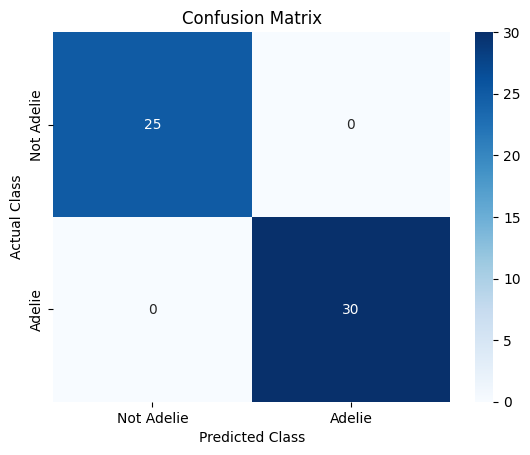

In [ ]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Adelie", "Adelie"],
    yticklabels=["Not Adelie", "Adelie"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
## Calculate Accuracy, Precision, Recall,F1-score
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


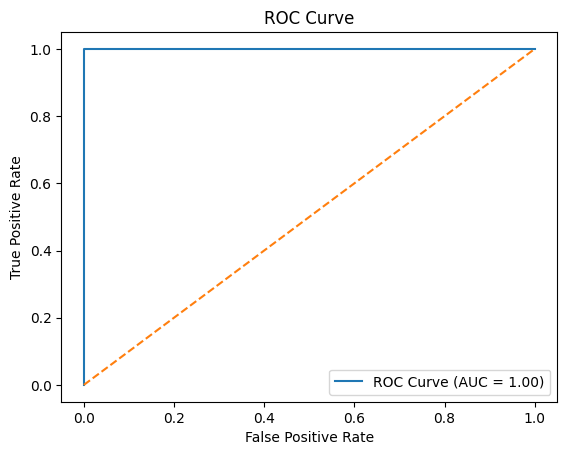

AUC Score: 1.0


In [ ]:
##Calculate FPR and TPR and Plot the ROC Curve
# Calculate False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("AUC Score:", roc_auc)

In [ ]:
# Analyse the Model Performance
print("Model Performance Analysis")

print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")
print(f"AUC Score: {roc_auc:.2f}")

if precision > recall:
    print("Precision is higher than recall.")
elif recall > precision:
    print("Recall is higher than precision.")
else:
    print("Precision and recall are equal.")

Model Performance Analysis
Accuracy: 1.00
Precision: 1.00
Recall: 1.00
F1-Score: 1.00
AUC Score: 1.00
Precision and recall are equal.


In [ ]:
# Display the Final Conclusion
print("Conclusion:")
print("Logistic Regression was implemented for binary classification")
print("using the Palmer Penguins dataset.")
print("The model predicted whether a penguin belongs to the")
print("Adelie class or the non-Adelie class.")
print("Performance was evaluated using the confusion matrix,")
print("accuracy, precision, recall, F1-score, ROC curve, and AUC.")

Conclusion:
Logistic Regression was implemented for binary classification
using the Palmer Penguins dataset.
The model predicted whether a penguin belongs to the
Adelie class or the non-Adelie class.
Performance was evaluated using the confusion matrix,
accuracy, precision, recall, F1-score, ROC curve, and AUC.
